# Data Preparation - `patients.csv`

In [1]:
# Import libraries
import math
import numpy as np
import pandas as pd
import seaborn as sns
import scipy.stats as stats
import matplotlib.pyplot as plt

from collections import defaultdict
from sklearn.preprocessing import MinMaxScaler

import seaborn as sns
from scipy.stats import pearsonr


In [10]:
# Loading Datasets
patients_df = pd.read_csv('../datasets/patients.csv')
icd10_df = pd.read_csv('../datasets/icd10_update_data.csv')
icd10_category_df = pd.read_csv('../datasets/icd10_category.csv')
len_init_patients = len(patients_df)

In [3]:
patients_df

,Unnamed: 0.1,Unnamed: 0,study_id,subject_id,ecg_time,ed_stay_id,ed_hadm_id,hosp_hadm_id,diagnosis,gender,age,anchor_year,anchor_age,dod,ecg_no_within_stay,ecg_taken_in_ed,ecg_taken_in_hosp,ecg_taken_in_ed_or_hosp,ts_ecg_path
0,0,0,40689238,10000032,2180-07-23 08:44:00,39399961.0,29079034.0,NaN,"['K7469', 'E871', 'R64', 'E875', 'I9581', 'J44...",F,52.0,2180.0,52.0,2180-09-09,0,True,False,True,./time-series/10000032_40689238
1,1,4,48446569,10000117,2183-09-18 13:52:00,33176849.0,27988844.0,NaN,"['E7800', 'K219', 'Z87442', 'S72012A', 'I341',...",F,57.0,2174.0,48.0,NaN,0,True,False,True,./time-series/10000117_48446569
2,2,14,47218930,10000764,2132-10-14 19:40:00,35420907.0,27897940.0,NaN,"['R040', 'D696', 'I252', 'E785', 'I214', 'E780...",M,86.0,2132.0,86.0,NaN,0,True,False,True,./time-series/10000764_47218930
3,3,35,42546971,10000980,2188-01-03 12:33:00,34277585.0,29654838.0,NaN,"['I248', 'E785', 'Z794', 'Z8673', 'J449', 'E11...",F,75.0,2186.0,73.0,2193-08-26,0,True,False,True,./time-series/10000980_42546971
4,4,66,40925049,10001176,2186-11-28 23:16:00,39677610.0,23334588.0,NaN,"['E871', 'R740', 'D649', 'E785', 'I10', 'K219'...",F,64.0,2186.0,64.0,NaN,0,True,False,True,./time-series/10001176_40925049
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
41410,41410,799921,43267699,19998444,2155-06-03 22:42:00,31817420.0,21096018.0,NaN,"['Z9049', 'F39', 'K219', 'F1021', 'R3911', 'K8...",M,38.0,2155.0,38.0,NaN,0,True,False,True,./time-series/19998444_43267699
41411,41411,799993,40314343,19999156,2123-01-27 13:35:00,39012698.0,22917423.0,NaN,"['R079', 'F419']",F,62.0,2123.0,62.0,NaN,0,True,False,True,./time-series/19999156_40314343
41412,41412,800023,42489677,19999733,2152-07-08 21:38:00,30940569.0,27674281.0,NaN,"['T7840XA', 'Y92099']",F,19.0,2152.0,19.0,NaN,0,True,False,True,./time-series/19999733_42489677
41413,41413,800024,40734999,19999784,2119-06-18 17:52:00,35692999.0,26194817.0,NaN,"['D649', 'D472', 'E440', 'D72819', 'Z6823', 'G...",M,57.0,2119.0,57.0,NaN,0,True,False,True,./time-series/19999784_40734999


## **Data Cleaning**


In [11]:
patients_df  = patients_df.drop(columns=["Unnamed: 0", 'Unnamed: 0.1', "ecg_taken_in_ed_or_hosp", 'ecg_taken_in_ed', 'ecg_no_within_stay', 'hosp_hadm_id', 'ed_hadm_id', 'ecg_taken_in_hosp', 'ts_ecg_path', 'ecg_time', 'anchor_year', 'anchor_age'])

In [4]:
patients_df.head()

,study_id,subject_id,ed_stay_id,diagnosis,gender,age,dod
0,40689238,10000032,39399961.0,"['K7469', 'E871', 'R64', 'E875', 'I9581', 'J44...",F,52.0,2180-09-09
1,48446569,10000117,33176849.0,"['E7800', 'K219', 'Z87442', 'S72012A', 'I341',...",F,57.0,NaN
2,47218930,10000764,35420907.0,"['R040', 'D696', 'I252', 'E785', 'I214', 'E780...",M,86.0,NaN
3,42546971,10000980,34277585.0,"['I248', 'E785', 'Z794', 'Z8673', 'J449', 'E11...",F,75.0,2193-08-26
4,40925049,10001176,39677610.0,"['E871', 'R740', 'D649', 'E785', 'I10', 'K219'...",F,64.0,NaN


In [4]:
patients_df.columns

Index(['study_id', 'subject_id', 'ed_stay_id', 'diagnosis', 'gender', 'age',
       'anchor_age', 'dod'],
      dtype='object')

In [5]:
# Statistiche per ogni NUMERICAL column per determinare anomalie
print(patients_df.describe())

           study_id    subject_id    ed_stay_id           age
count  4.141500e+04  4.141500e+04  4.141500e+04  41415.000000
mean   4.498888e+07  1.501484e+07  3.501692e+07     61.982953
std    2.883970e+06  2.892611e+06  2.893167e+06     18.827568
min    4.000004e+07  1.000003e+07  3.000004e+07     18.000000
25%    4.250011e+07  1.250300e+07  3.251014e+07     50.000000
50%    4.496857e+07  1.502321e+07  3.502889e+07     64.000000
75%    4.748375e+07  1.752916e+07  3.753689e+07     77.000000
max    4.999984e+07  1.999999e+07  3.999994e+07    100.000000


In [12]:
# Conta e calcola la percentuale di valori mancanti
missing_values = patients_df.isnull().sum()
missing_percentage = (missing_values / len(patients_df)) * 100
print(pd.DataFrame({'Missing val': missing_values, '    |     Missing %': missing_percentage}))


            Missing val      |     Missing %
study_id              0             0.000000
subject_id            0             0.000000
ed_stay_id            0             0.000000
diagnosis             0             0.000000
gender                0             0.000000
age                   0             0.000000
dod               33405            80.659181


#### Dei pazienti che ho nel dataset sono maggiormente vivi

In [13]:
# Sostituzione i NaN in 'dod' con '0000-00-00'
patients_df['dod'] = patients_df['dod'].fillna('0000-00-00')

In [14]:
patients_df['dod'] = np.where(patients_df['dod'] == '0000-00-00', 0, 1)

In [15]:
patients_df['dod'].unique()

array([1, 0])

In [16]:
patients_df['gender'] = patients_df['gender'].map({'M': 0, 'F': 1})

---
#### Age range. faccio rientrare i pazienti in intervalli di eta. range: 10

In [17]:
intervallo = 10
def get_age_range(age):
    lower_bound = (age // intervallo) * intervallo
    upper_bound = lower_bound + intervallo
    return f"{int(lower_bound)}-{int(upper_bound)}"

patients_df['age_range'] = patients_df['age'].apply(get_age_range)
print(patients_df[['age', 'age_range']].head())


    age age_range
0  52.0     50-60
1  57.0     50-60
2  86.0     80-90
3  75.0     70-80
4  64.0     60-70


In [20]:
patients_df

,study_id,subject_id,ed_stay_id,diagnosis,gender,dod,age_range
0,40689238,10000032,39399961.0,"['K7469', 'E871', 'R64', 'E875', 'I9581', 'J44...",1,1,50.0-60.0
1,48446569,10000117,33176849.0,"['E7800', 'K219', 'Z87442', 'S72012A', 'I341',...",1,0,50.0-60.0
2,47218930,10000764,35420907.0,"['R040', 'D696', 'I252', 'E785', 'I214', 'E780...",0,0,80.0-90.0
3,42546971,10000980,34277585.0,"['I248', 'E785', 'Z794', 'Z8673', 'J449', 'E11...",1,1,70.0-80.0
4,40925049,10001176,39677610.0,"['E871', 'R740', 'D649', 'E785', 'I10', 'K219'...",1,0,60.0-70.0
...,...,...,...,...,...,...,...
41410,43267699,19998444,31817420.0,"['Z9049', 'F39', 'K219', 'F1021', 'R3911', 'K8...",0,0,30.0-40.0
41411,40314343,19999156,39012698.0,"['R079', 'F419']",1,0,60.0-70.0
41412,42489677,19999733,30940569.0,"['T7840XA', 'Y92099']",1,0,10.0-20.0
41413,40734999,19999784,35692999.0,"['D649', 'D472', 'E440', 'D72819', 'Z6823', 'G...",0,0,50.0-60.0


---
#### Associazione delle categorie ad ogni paziente creando una lista contenente quelle in cui rientrano

In [18]:
patients_df['diagnosis'] = patients_df['diagnosis'].apply(eval)

In [19]:
def get_categories(codes, category_ranges):
    categories = set()  
    for code in codes:
        code = code[:3]
        for _, row in category_ranges.iterrows():
            start, end = row['Code_range'].split('-')
            if start <= code <= end:
                categories.add(row['Code_range'])
                break
    return list(categories)

patients_df['diagnosis_categories'] = patients_df['diagnosis'].apply(
    lambda codes: get_categories(codes, icd10_category_df)
)
patients_df['num_categories'] = patients_df['diagnosis_categories'].apply(len)

patients_df[['diagnosis', 'diagnosis_categories']].head()


,diagnosis,diagnosis_categories
0,"[K7469, E871, R64, E875, I9581, J449, R188, V4...","[A00-B99, I00-I99, K00-K95, V00-Y99, Z00-Z99, ..."
1,"[E7800, K219, Z87442, S72012A, I341, Z7901, Y9...","[M00-M99, I00-I99, K00-K95, G00-G99, Z00-Z99, ..."
2,"[R040, D696, I252, E785, I214, E780, I2510, Y9...","[I00-I99, N00-N99, V00-Y99, Z00-Z99, S00-T88, ..."
3,"[I248, E785, Z794, Z8673, J449, E119, I129, N1...","[I00-I99, N00-N99, Z00-Z99, J00-J99, E00-E89]"
4,"[E871, R740, D649, E785, I10, K219, R197, E119...","[I00-I99, K00-K95, G00-G99, D50-D89, J00-J99, ..."


In [21]:
patients_df[['subject_id', "gender", 'diagnosis', 'age_range', 'diagnosis_categories', 'num_categories']]

,subject_id,gender,diagnosis,age_range,diagnosis_categories,num_categories
0,10000032,1,"[K7469, E871, R64, E875, I9581, J449, R188, V4...",50-60,"[A00-B99, I00-I99, K00-K95, V00-Y99, Z00-Z99, ...",9
1,10000117,1,"[E7800, K219, Z87442, S72012A, I341, Z7901, Y9...",50-60,"[M00-M99, I00-I99, K00-K95, G00-G99, Z00-Z99, ...",9
2,10000764,0,"[R040, D696, I252, E785, I214, E780, I2510, Y9...",80-90,"[I00-I99, N00-N99, V00-Y99, Z00-Z99, S00-T88, ...",8
3,10000980,1,"[I248, E785, Z794, Z8673, J449, E119, I129, N1...",70-80,"[I00-I99, N00-N99, Z00-Z99, J00-J99, E00-E89]",5
4,10001176,1,"[E871, R740, D649, E785, I10, K219, R197, E119...",60-70,"[I00-I99, K00-K95, G00-G99, D50-D89, J00-J99, ...",8
...,...,...,...,...,...,...
41410,19998444,0,"[Z9049, F39, K219, F1021, R3911, K861, R52, R1...",30-40,"[K00-K95, G00-G99, Z00-Z99, F01-F99, R00-R99]",5
41411,19999156,1,"[R079, F419]",60-70,"[F01-F99, R00-R99]",2
41412,19999733,1,"[T7840XA, Y92099]",10-20,"[V00-Y99, S00-T88]",2
41413,19999784,0,"[D649, D472, E440, D72819, Z6823, G959, J3801,...",50-60,"[M00-M99, G00-G99, C00-D49, Z00-Z99, D50-D89, ...",8


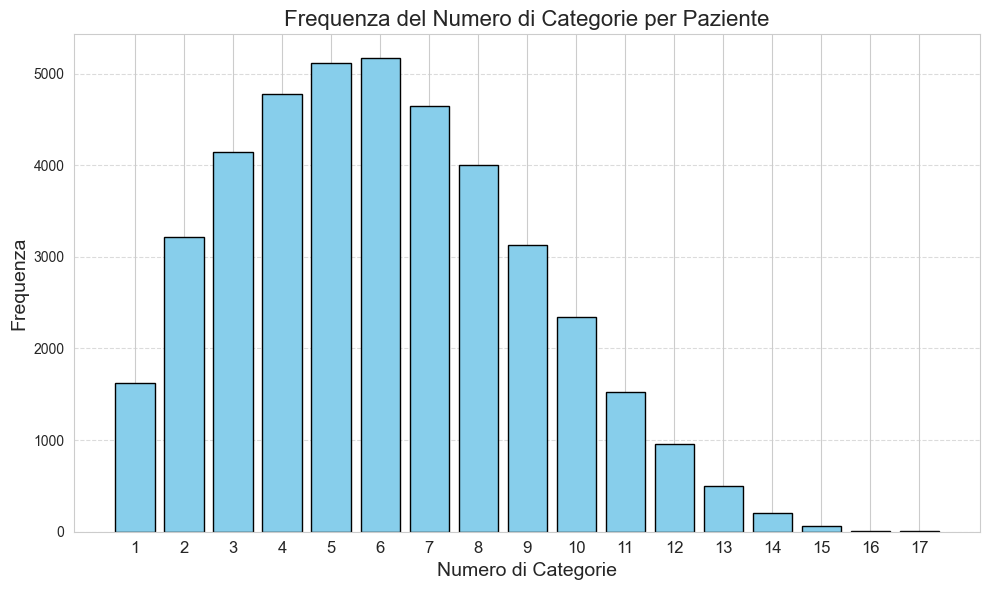

In [14]:
category_counts = patients_df['num_categories'].value_counts().sort_index()

plt.figure(figsize=(10, 6))
plt.bar(category_counts.index, category_counts.values, color='skyblue', edgecolor='black')

plt.title("Frequenza del Numero di Categorie per Paziente", fontsize=16)
plt.xlabel("Numero di Categorie", fontsize=14)
plt.ylabel("Frequenza", fontsize=14)
plt.xticks(category_counts.index, fontsize=12)
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()


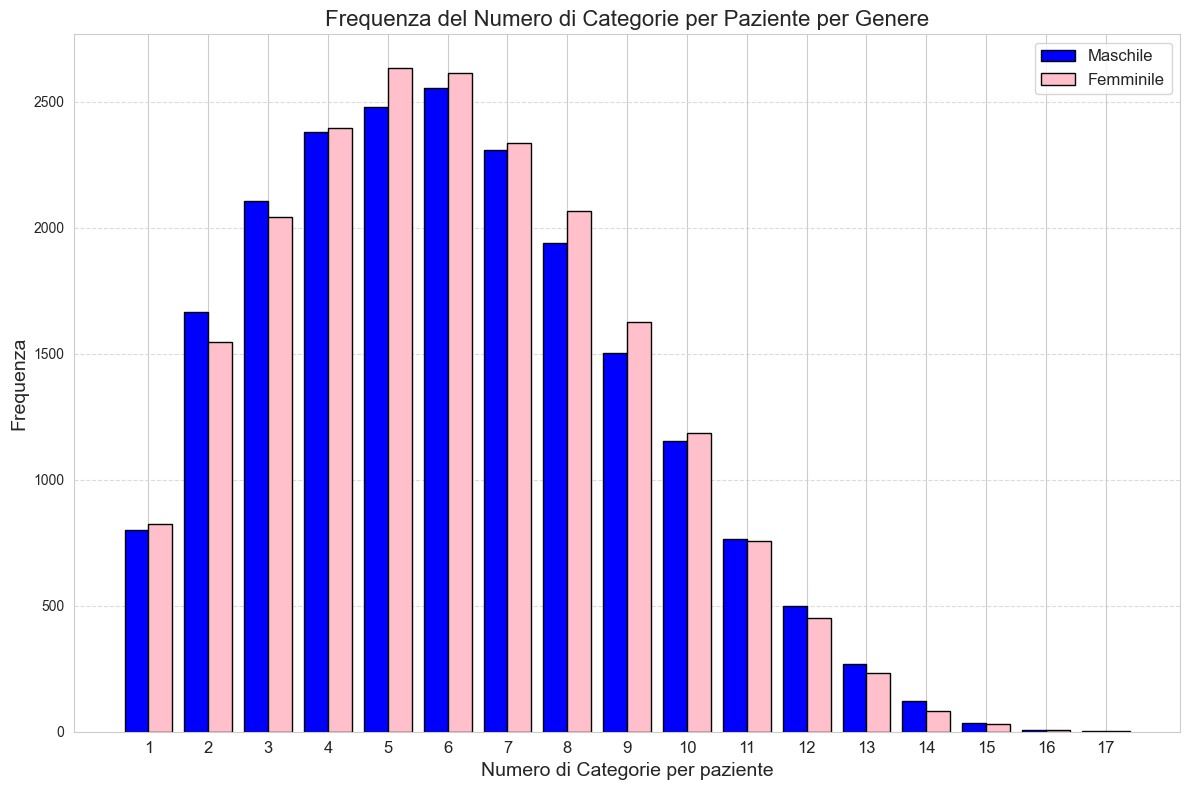

In [28]:
# Raggruppa i dati per genere e calcola il numero di categorie
gender_groups = patients_df.groupby('gender')['num_categories']
category_counts_m = gender_groups.get_group(0).value_counts().sort_index()
category_counts_f = gender_groups.get_group(1).value_counts().sort_index()

plt.figure(figsize=(12, 8))
plt.bar(category_counts_m.index - 0.2, category_counts_m.values, width=0.4, label='Maschile', color='blue', edgecolor='black')
plt.bar(category_counts_f.index + 0.2, category_counts_f.values, width=0.4, label='Femminile', color='pink', edgecolor='black')
plt.title("Frequenza del Numero di Categorie per Paziente per Genere", fontsize=16)
plt.xlabel("Numero di Categorie per paziente", fontsize=14)
plt.ylabel("Frequenza", fontsize=14)
plt.xticks(category_counts_m.index, fontsize=12)
plt.legend(fontsize=12)
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()


In [30]:
# Funzione per calcolare il range di età
intervallo = 20
def get_age_range(age):
    lower_bound = (age // intervallo) * intervallo  
    upper_bound = lower_bound + intervallo  
    return f"{int(lower_bound)}-{int(upper_bound)}"

patients_df['age_range'] = patients_df['age'].apply(get_age_range)
print(patients_df[['age', 'age_range']].head())

    age age_range
0  52.0     40-60
1  57.0     40-60
2  86.0    80-100
3  75.0     60-80
4  64.0     60-80


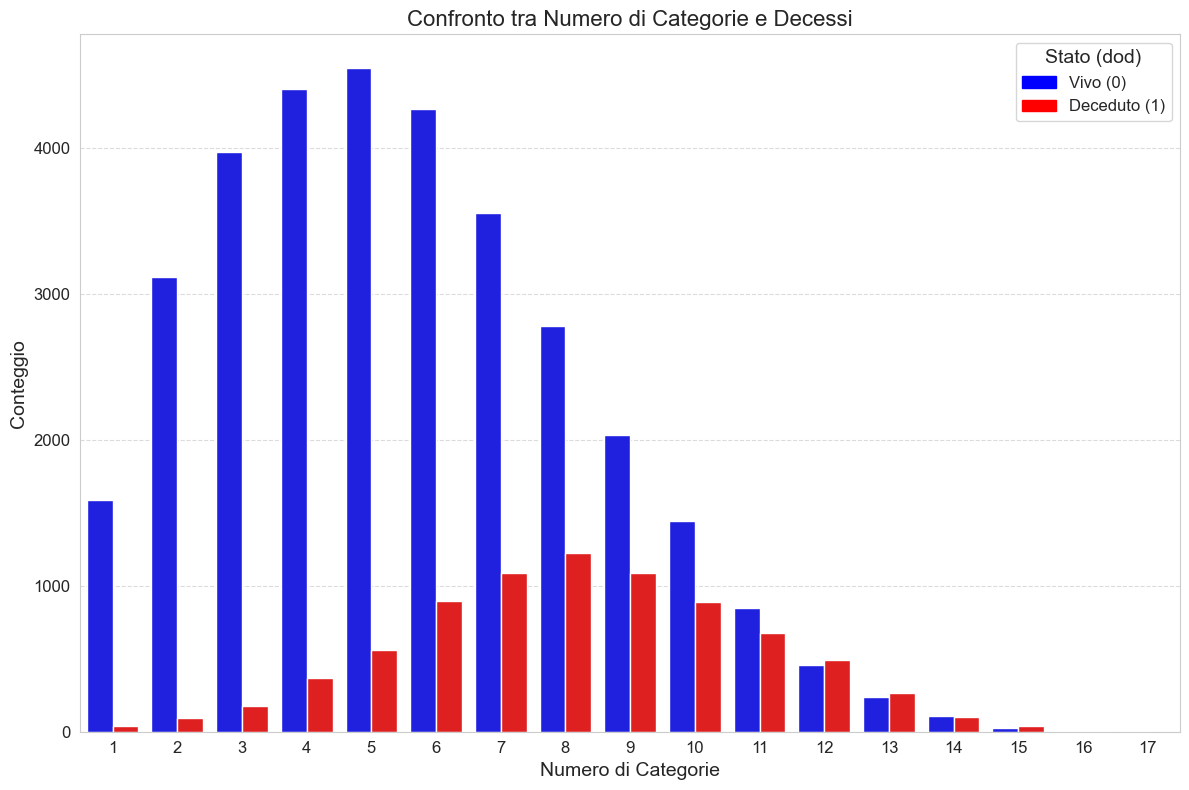

In [19]:
counts_df = patients_df.groupby(['num_categories', 'dod']).size().reset_index(name='count')

plt.figure(figsize=(12, 8))
sns.barplot(
    data=counts_df,
    x='num_categories',
    y='count',
    hue='dod',
    palette={0: 'blue', 1: 'red'}  # Blu per i vivi, rosso per i morti
)

plt.title("Confronto tra Numero di Categorie e Decessi", fontsize=16)
plt.xlabel("Numero di Categorie", fontsize=14)
plt.ylabel("Conteggio", fontsize=14)
legend_labels = ['Vivo (0)', 'Deceduto (1)']
legend_colors = ['blue', 'red']
handles = [plt.Rectangle((0, 0), 1, 1, color=color) for color in legend_colors]
plt.legend(handles, legend_labels, title="Stato (dod)", fontsize=12, title_fontsize=14)
plt.xticks(fontsize=12)
plt.yticks(fontsize=12)
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()


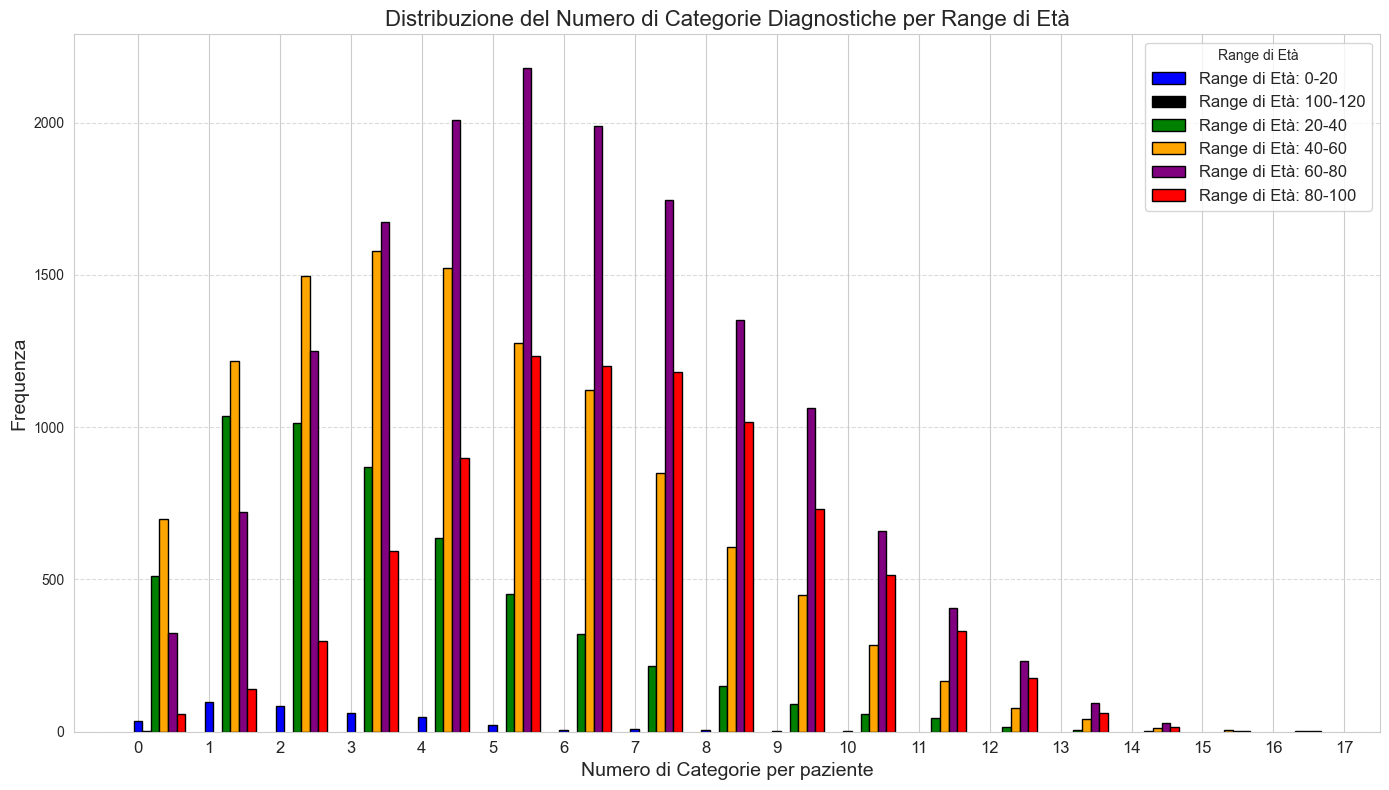

In [41]:
age_range_colors = {
    '0-20': 'blue',
    '20-40': 'green',
    '40-60': 'orange',
    '60-80': 'purple',
    '80-100': 'red',
    '100-120': 'black'
}

# Raggruppa i dati per range di età e calcola la distribuzione
age_range_groups = patients_df.groupby('age_range')

plt.figure(figsize=(14, 8))
bar_width = 0.22  # Larghezza di ogni barra
space_between_categories = 0.5  # Spazio tra diversi numeri di categorie
max_categories = patients_df['num_categories'].max()
base_positions = np.arange(max_categories + 1) * (bar_width * len(age_range_groups) + space_between_categories)

# Aggiungi barre per ciascun range di età
for i, (age_range, group) in enumerate(age_range_groups):
    category_counts = group['num_categories'].value_counts().sort_index()
    positions = base_positions + i * bar_width
    color = age_range_colors.get(age_range, 'gray') 
    plt.bar(positions[:len(category_counts)], category_counts.values, width=bar_width,
            label=f"Range di Età: {age_range}", color=color, edgecolor='black')

plt.title("Distribuzione del Numero di Categorie Diagnostiche per Range di Età", fontsize=16)
plt.xlabel("Numero di Categorie per paziente", fontsize=14)
plt.ylabel("Frequenza", fontsize=14)
plt.xticks(base_positions, range(max_categories + 1), fontsize=12)
plt.legend(fontsize=12, title="Range di Età")
plt.grid(axis='y', linestyle='--', alpha=0.7)

plt.tight_layout()
plt.show()


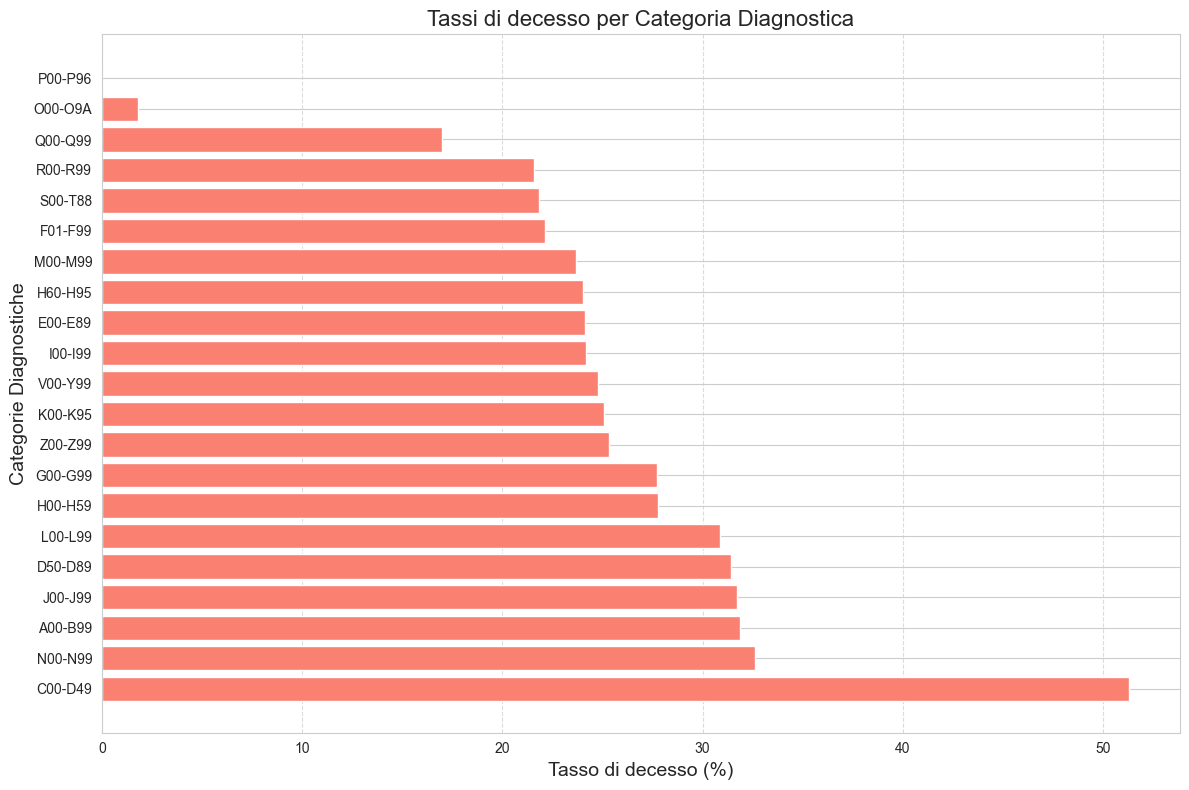

In [42]:
patients_expanded = patients_df.explode('diagnosis_categories')
# Calcola il numero totale di pazienti e il numero di deceduti per categoria
diagnosis_death_stats = patients_expanded.groupby('diagnosis_categories').agg(
    total_patients=('subject_id', 'count'),
    total_deaths=('dod', 'sum')  # Somma i valori di 'dod', dove 1 = deceduto
).reset_index()
# Calcola il tasso di decesso per categoria
diagnosis_death_stats['death_rate'] = (diagnosis_death_stats['total_deaths'] /
                                       diagnosis_death_stats['total_patients']) * 100

# Ordina le categorie per tasso di decesso
diagnosis_death_stats = diagnosis_death_stats.sort_values(by='death_rate', ascending=False)
plt.figure(figsize=(12, 8))
plt.barh(diagnosis_death_stats['diagnosis_categories'], diagnosis_death_stats['death_rate'], color='salmon')
plt.xlabel("Tasso di decesso (%)", fontsize=14)
plt.ylabel("Categorie Diagnostiche", fontsize=14)
plt.title("Tassi di decesso per Categoria Diagnostica", fontsize=16)
plt.grid(axis='x', linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()


In [44]:
icd10_category_df

,Code_range,Description
0,A00-B99,Certain infectious and parasitic diseases
1,C00-D49,Neoplasms
2,D50-D89,Diseases of the blood and blood-forming organs...
3,E00-E89,"Endocrine, nutritional and metabolic diseases"
4,F01-F99,"Mental, Behavioral and Neurodevelopmental diso..."
5,G00-G99,Diseases of the nervous system
6,H00-H59,Diseases of the eye and adnexa
7,H60-H95,Diseases of the ear and mastoid process
8,I00-I99,Diseases of the circulatory system
9,J00-J99,Diseases of the respiratory system


---

### SAVE clean data patients_df

In [59]:
patients_df.to_csv('../datasets/patients_cleaned.csv', index=False)

---
### **Normalizzazione**

In [57]:
patients_df.columns

Index(['study_id', 'subject_id', 'ed_stay_id', 'diagnosis', 'gender', 'age',
       'dod', 'age_range', 'diagnosis_categories', 'num_categories'],
      dtype='object')

In [50]:
features = ['gender', 'dod', 'age', 'num_categories']

In [51]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()
normalized_patients_df = pd.DataFrame()
normalized_patients_df = scaler.fit_transform(patients_df[features])

---
### **Matrix correlation**

In [53]:
normalized_patients_df = pd.DataFrame(normalized_patients_df, columns=features)

In [55]:
normalized_patients_df.columns

Index(['gender', 'dod', 'age', 'num_categories'], dtype='object')

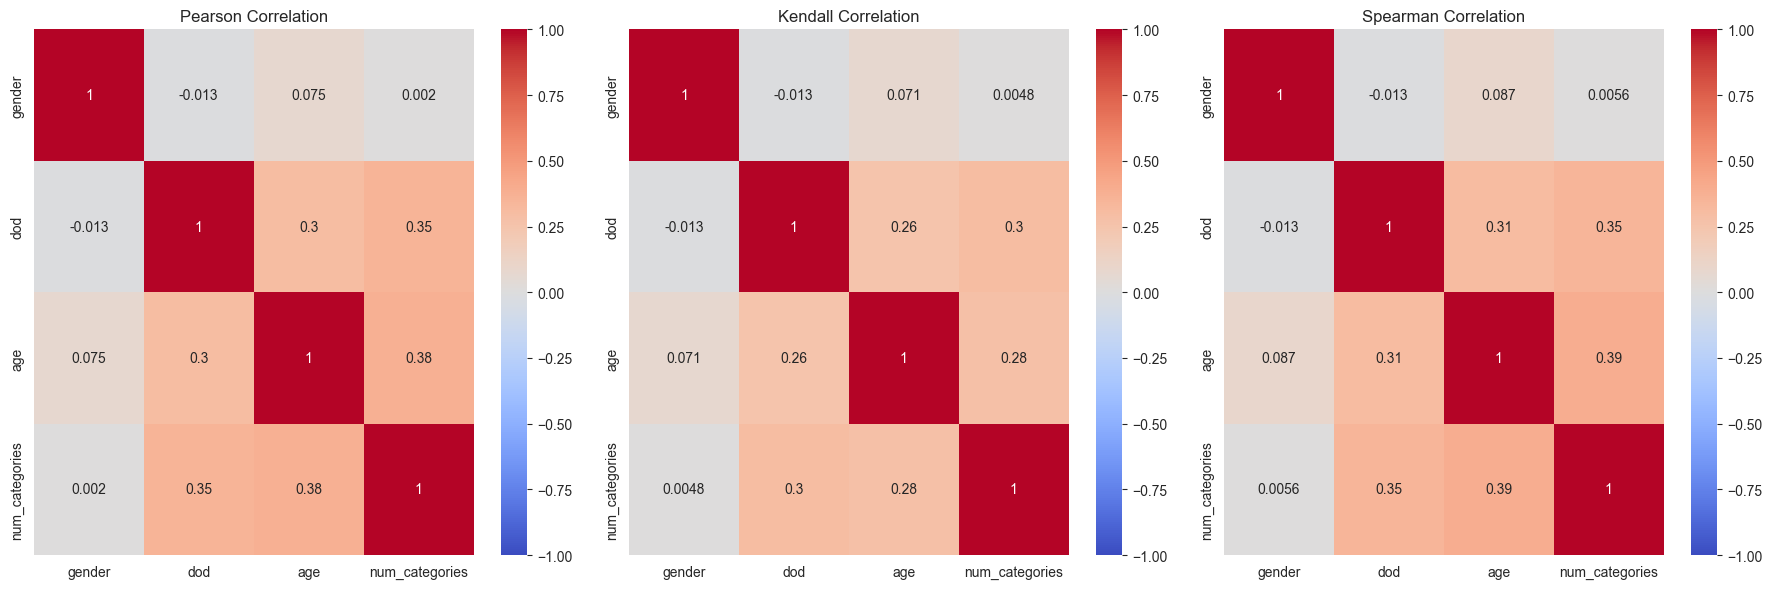

In [58]:
correlation_pearson = patients_df[features].corr(method='pearson')
correlation_kendall = patients_df[features].corr(method='kendall')
correlation_spearman = patients_df[features].corr(method='spearman')

correlation_matrices = [correlation_pearson, correlation_kendall, correlation_spearman]
titles = ['Pearson Correlation', 'Kendall Correlation', 'Spearman Correlation']

fig, axes = plt.subplots(1, 3, figsize=(18, 6))
for idx, (matrix, title) in enumerate(zip(correlation_matrices, titles)):
    sns.heatmap(matrix, annot=True, cmap='coolwarm', vmin=-1, vmax=1, ax=axes[idx])
    axes[idx].set_title(title)
plt.tight_layout()
plt.show()